## Read Data

In [61]:
import pandas as pd

In [62]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/collaborations/Tomas/input.csv' # work laptop
TARGET_DF_PATH =  f'{DATA_PATH_BASE}/collaborations/Tomas/target.csv' # work laptop

RESULT_PATH =  f'{DATA_PATH_BASE}/collaborations/Tomas/mutated_tomas.csv' # work laptop

df = pd.read_csv(DATA_PATH)

In [63]:
df

,peptide
0,YRGYSLGNWVCAAKFE
1,CAAKFESNFNTQATNRNTDGSTDY
2,NTDGSTDYGILQINSR
3,NLCNIPCSALLSSDI


In [64]:
df['peptide_len'] = df.peptide.str.len()

In [65]:
df

,peptide,peptide_len
0,YRGYSLGNWVCAAKFE,16
1,CAAKFESNFNTQATNRNTDGSTDY,24
2,NTDGSTDYGILQINSR,16
3,NLCNIPCSALLSSDI,15


Distribution of lengths

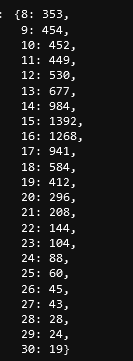

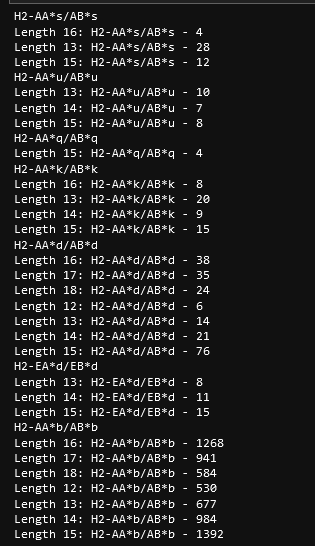

In [46]:
'CAAKFESNFNTQATNRNTDGSTDY'.find('FESNFNTQA')
    

4

In [47]:
target_peptides = list()
source_peptides = list()

target_length = 15

for peptide in df.peptide.values:
    if len(peptide) > 16:
        for start_index in range(len(peptide)-target_length+1):
            target_peptide = peptide[start_index:start_index + target_length]
            target_peptides.append(target_peptide)
            source_peptides.append(peptide)
    else:
        target_peptides.append(peptide)
        source_peptides.append(peptide)
    print(peptide)

YRGYSLGNWVCAAKFE
CAAKFESNFNTQATNRNTDGSTDY
NTDGSTDYGILQINSR
NLCNIPCSALLSSDI


In [48]:
target_df = pd.DataFrame({"source_peptide":source_peptides, "peptide":target_peptides, "peptide_len":[len(pep) for pep in target_peptides]})

In [49]:
target_df

,source_peptide,peptide,peptide_len
0,YRGYSLGNWVCAAKFE,YRGYSLGNWVCAAKFE,16
1,CAAKFESNFNTQATNRNTDGSTDY,CAAKFESNFNTQATN,15
2,CAAKFESNFNTQATNRNTDGSTDY,AAKFESNFNTQATNR,15
3,CAAKFESNFNTQATNRNTDGSTDY,AKFESNFNTQATNRN,15
4,CAAKFESNFNTQATNRNTDGSTDY,KFESNFNTQATNRNT,15
5,CAAKFESNFNTQATNRNTDGSTDY,FESNFNTQATNRNTD,15
6,CAAKFESNFNTQATNRNTDGSTDY,ESNFNTQATNRNTDG,15
7,CAAKFESNFNTQATNRNTDGSTDY,SNFNTQATNRNTDGS,15
8,CAAKFESNFNTQATNRNTDGSTDY,NFNTQATNRNTDGST,15
9,CAAKFESNFNTQATNRNTDGSTDY,FNTQATNRNTDGSTD,15


In [50]:
target_df.to_csv(TARGET_DF_PATH, sep=";", index=False)

In [51]:
MODELS_DESCRIPTIONS = {

         "mouse_model": {
        "path": "experiment_results/core_identification_Tom/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'H2-AA*b/AB*b', 
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [ 12, 13,14,15,16,17, 18],
        "core_start_state": [],
        "core_end_state": [7],
        "need_to_delete": [8]

    },











    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [52]:
ALLELES = ['H2-AA*b/AB*b']
OLD_ALLELES = ['H2-AA*b/AB*b']
RUNS = 10
TOTAL_SPLITS = 1
models_to_read= ['v']

selected_models = [
     "mouse_model"
]


In [53]:
from hmm_logic_methods import load_model

In [54]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(OLD_ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [55]:
per_name_binding_model.keys()

dict_keys(['0_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '1_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '2_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '3_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '4_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '5_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '6_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '7_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '8_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0', '9_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-H2_AA_b_AB_b-0'])

## Viterbi path

In [56]:
import numpy as np
source_peptides = np.unique(source_peptides)

per_peptide_df = dict()
for peptide in source_peptides:
    paths = list()
    for key, model in per_name_binding_model.items():
        prob ,path = model.viterbi(peptide)
        paths.append([item[1].name for item in path])
        df = pd.DataFrame(paths)
        per_peptide_df[peptide] = df
    

In [57]:
per_peptide_df[source_peptides[0]]

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s009,s007,...,s006,s008,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
1,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s009,s007,...,s006,s008,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
2,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s009,s007,...,s006,s008,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
3,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s009,s007,...,s006,s008,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
4,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s007,s000,...,s008,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
5,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s007,s000,...,s008,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
6,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s007,s000,...,s008,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
7,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s007,s000,...,s008,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
8,grouped_model-start,s009,s009,s009,s009,s009,s009,s009,s007,s000,...,s008,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end
9,grouped_model-start,s009,s009,s009,s009,s009,s009,s007,s000,s001,...,s010,s010,s010,s010,s010,s010,s010,s010,s010,grouped_model-end


In [65]:
from collections import defaultdict

source_peptides = list(source_peptides)

peptide_to_core_options = defaultdict(list)


cores = list()
for peptide in source_peptides:
    if peptide == "CAAKFESNFNTQATNRNTDGSTDY":
        peptide_to_core_options[peptide].append('FNTQATNRN')
        peptide_to_core_options[peptide].append('FESNFNTQA')
    elif peptide == "NLCNIPCSALLSSDI":
        peptide_to_core_options[peptide].append('NIPCSALLS')
    elif peptide == "NTDGSTDYGILQINSR":
        peptide_to_core_options[peptide].append('TDYGILQIN')
        peptide_to_core_options[peptide].append('STDYGILQI')
    elif peptide == "YRGYSLGNWVCAAKFE":
        peptide_to_core_options[peptide].append('SLGNWVCAA')
        peptide_to_core_options[peptide].append('YSLGNWVCA')

assert len(peptide_to_core_options) == len(source_peptides)

In [66]:
start_indexes = list()
peptide_to_core_to_start_index = dict()
for peptide in source_peptides:
    peptide_to_core_to_start_index[peptide] = dict()
    for core in peptide_to_core_options[peptide]:
        peptide_to_core_to_start_index[peptide][core] = peptide.find(core)
    

# for peptide, core in zip(source_peptides, cores):
#     start_indexes.append(peptide.find(core))

In [67]:
peptide_to_core_to_start_index

{'CAAKFESNFNTQATNRNTDGSTDY': {'FNTQATNRN': 8, 'FESNFNTQA': 4},
 'NLCNIPCSALLSSDI': {'NIPCSALLS': 3},
 'NTDGSTDYGILQINSR': {'TDYGILQIN': 5, 'STDYGILQI': 4},
 'YRGYSLGNWVCAAKFE': {'SLGNWVCAA': 4, 'YSLGNWVCA': 3}}

In [68]:
'CAAKFESNFNTQATNRNTDGSTDY'[8:8+9]

'FNTQATNRN'

In [69]:
'CAAKFESNFNTQATNRNTDGSTDY'.find('FNTQATNRN')

8

In [70]:
pos_to_options = {
    0: ['R', 'N', 'K', 'D'],
    3: ['R', 'M', 'Q', 'L', 'K', 'H', 'E'],
    5: ['E', 'H', 'R', 'K', 'M', 'W', 'Q'],
    8: ['K', 'W']
}

all_options = [(key, option) for key, option_list in pos_to_options.items() for option in option_list]



In [71]:
len(all_options)

20

In [105]:
source_peptides

['CAAKFESNFNTQATNRNTDGSTDY',
 'NLCNIPCSALLSSDI',
 'NTDGSTDYGILQINSR',
 'YRGYSLGNWVCAAKFE']

In [106]:
# single core single options

original_peptides = list()
mutated_peptides = list()
for peptide in source_peptides:
    original_peptides.append(peptide)
    mutated_peptides.append(peptide)
    
for pep_ind, peptide in enumerate(source_peptides):
    pep_list = list(peptide)
    for core_option in peptide_to_core_options[peptide]:
        core_start = peptide_to_core_to_start_index[peptide][core_option]
        for pos, options in pos_to_options.items():
            for option in options:
                cur_list = pep_list.copy()
                cur_list[core_start + pos] = option
                mutated_peptides.append("".join(cur_list))
                original_peptides.append(peptide)

In [107]:
from itertools import combinations


# single core double options 

for pep_ind, peptide in enumerate(source_peptides):
    pep_list = list(peptide)
    for core_option in peptide_to_core_options[peptide]:
        core_start = peptide_to_core_to_start_index[peptide][core_option]
        for item in combinations(all_options, 2):
            pos1, option1 = item[0]
            pos2, option2 = item[1]
            if pos1 != pos2:
                cur_list = pep_list.copy()
                cur_list[core_start + pos1] = option1
                cur_list[core_start + pos2] = option2
                mutated_peptides.append("".join(cur_list))
                original_peptides.append(peptide)


In [108]:
len(mutated_peptides)

1131

In [109]:
# change all cores in all simultaniously
#  single options

for pep_ind, peptide in enumerate(source_peptides):
    pep_list = list(peptide)
    core_starts = list()
    for core_option in peptide_to_core_options[peptide]:
        cur_core_start = peptide_to_core_to_start_index[peptide][core_option]
        core_starts.append(cur_core_start)
    for pos, options in pos_to_options.items():
        for option in options:
            cur_list = pep_list.copy()
            for core_start in core_starts:
                cur_list[core_start + pos] = option
            mutated_peptides.append("".join(cur_list))
            original_peptides.append(peptide)

In [110]:
len(mutated_peptides)

1211

In [111]:
# double substitutions

for pep_ind, peptide in enumerate(source_peptides):
    pep_list = list(peptide)
    core_starts = list()
    for core_option in peptide_to_core_options[peptide]:
        cur_core_start = peptide_to_core_to_start_index[peptide][core_option]
        core_starts.append(cur_core_start)
    for item in combinations(all_options, 2):
        pos1, option1 = item[0]
        pos2, option2 = item[1]
        if pos1 != pos2:
            cur_list = pep_list.copy()
            for core_start in core_starts:
                cur_list[core_start + pos1] = option1
                cur_list[core_start + pos2] = option2
            mutated_peptides.append("".join(cur_list))
            original_peptides.append(peptide)

In [112]:
len(mutated_peptides)

1775

In [113]:
len(mutated_peptides)

1775

In [114]:
df =pd.DataFrame({'peptide': mutated_peptides, 'original_peptide':original_peptides})

In [115]:
len(np.unique(mutated_peptides))

1567

In [118]:
df.to_csv(RESULT_PATH, sep=";", index=False)

In [ ]:
start_indexes[0]

In [37]:
pos_to_options

{0: ['R', 'N', 'K', 'D'],
 3: ['R', 'M', 'Q', 'L', 'K', 'H', 'E'],
 5: ['E', 'H', 'R', 'K', 'M', 'W', 'Q'],
 8: ['K', 'W']}

In [39]:
source_peptides[0][8:]

'FNTQATNRNTDGSTDY'

## Visualize matrices

In [66]:
ALLELE_FILES= "G:/My Drive/Work/ITMO/data/Binding data/MixMHCpred/PWMdef_Mouse/"
# Allele s
s = """H2_Aa_b__H2_Ab_b	H2-IAb
H2_Aa_d__H2_Ab_d	H2-IAd
H2_Aa_f__H2_Ab_f	H2-IAf
H2_Aa_g7__H2_Ab_g7	H2-IAg7
H2_Aa_k__H2_Ab_k	H2-IAk
H2_Aa_nb1__H2_Ab_nb1	H2-IAnb1
H2_Aa_q__H2_Ab_q	H2-IAq
H2_Aa_r__H2_Ab_r	H2-IAr
H2_Aa_s__H2_Ab_s	H2-IAs
H2_Aa_s2__H2_Ab_s2	H2-IAs2
H2_Aa_u__H2_Ab_u	H2-IAu
H2_Ea_d__H2_Eb_d	H2-IEd
H2_Ea_k__H2_Eb_k	H2-IEk"""

In [67]:
lines = s.split('\n')

In [68]:
allele_to_file_prefix = {
   allele_name: prefix  for prefix, allele_name in [tuple( res for res in line.split('\t')) for line in  s.split('\n') ]
}

In [69]:
allele_to_file_prefix

{'H2-IAb': 'H2_Aa_b__H2_Ab_b',
 'H2-IAd': 'H2_Aa_d__H2_Ab_d',
 'H2-IAf': 'H2_Aa_f__H2_Ab_f',
 'H2-IAg7': 'H2_Aa_g7__H2_Ab_g7',
 'H2-IAk': 'H2_Aa_k__H2_Ab_k',
 'H2-IAnb1': 'H2_Aa_nb1__H2_Ab_nb1',
 'H2-IAq': 'H2_Aa_q__H2_Ab_q',
 'H2-IAr': 'H2_Aa_r__H2_Ab_r',
 'H2-IAs': 'H2_Aa_s__H2_Ab_s',
 'H2-IAs2': 'H2_Aa_s2__H2_Ab_s2',
 'H2-IAu': 'H2_Aa_u__H2_Ab_u',
 'H2-IEd': 'H2_Ea_d__H2_Eb_d',
 'H2-IEk': 'H2_Ea_k__H2_Eb_k'}

In [179]:
target_allele = "H2-IEk"

In [180]:
allele_df = pd.read_csv(f"{ALLELE_FILES}{allele_to_file_prefix[target_allele]}.txt", sep='\t', index_col=0)

In [181]:
allele_df = allele_df.T

In [182]:
allele_df = allele_df.reset_index(drop=True)

In [183]:
import logomaker
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

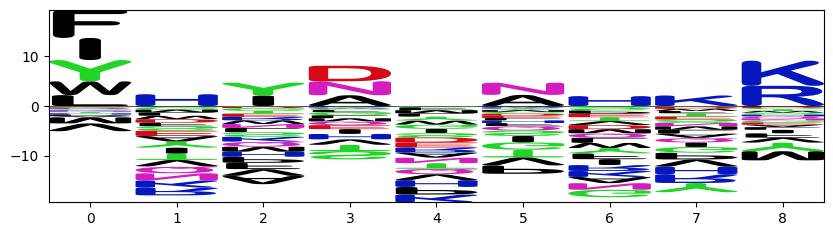

In [184]:
import numpy as np
info_matrix = allele_df.copy()

#info_matrix = info_matrix[info_matrix> 0.1]
info_matrix[info_matrix<=1.9] = -info_matrix[info_matrix<2] 
    
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, fade_below=False,  #stack_order='small_on_top'
                        )


In [178]:
info_matrix

PWM_norm.1,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,-0.3124,-0.1824,-0.1293,-0.1114,7.5532,-0.1680,-0.4852,1.9451,-0.1544,-1.3720,-0.4136,-0.2307,-0.4814,-0.1173,-0.1424,-0.1172,-0.1877,-0.6949,4.1777,10.1707
1,-0.4180,-0.1821,-1.1606,-1.1767,-1.0322,-0.2978,4.4838,-1.1484,2.1099,-0.7444,-0.3233,-0.6348,-0.1500,-0.8790,-1.4115,-0.8766,-0.7088,-1.5729,-0.3737,-1.4092
2,-1.3010,-0.2189,-0.4127,-0.7602,-1.1378,-0.3149,-0.8469,2.6797,-1.7822,-0.8512,-1.4383,-0.4687,-1.1029,-0.2965,-1.2318,-1.3309,-1.0490,-0.8280,-0.5294,-0.6702
3,-0.2821,-0.5649,-0.2902,-0.4427,-0.8315,-0.2085,-0.8249,-1.7393,3.2389,-0.2753,-0.6360,4.0859,-0.1449,-0.7639,2.6069,-0.2207,-0.6739,-1.6760,2.8229,-0.9044
4,-1.6184,-0.3913,-1.3855,-0.8684,-0.2100,-0.4696,3.0648,-0.4399,-1.8228,-0.4673,-1.0250,-1.2449,-1.3490,-1.1862,-1.1964,-0.5916,-1.7257,-0.5443,-0.1520,-0.2729
5,-0.7259,-0.2283,-0.2108,-0.5726,-0.3858,-0.3388,-1.3020,4.6219,-0.3898,-0.8760,-0.4967,-0.7031,-0.2746,-0.7377,2.0946,-0.5125,-1.4859,2.5595,-0.1809,-1.0339
6,-0.7631,-0.1667,-0.8829,-1.2938,-0.3924,-0.2277,2.9654,-0.5871,-1.1839,-0.4928,-0.3451,3.5683,2.2546,-1.7293,-0.5882,-0.5439,-0.4288,-0.5150,-0.1913,2.4049
7,-0.7619,-0.1896,-0.3247,-0.5643,-0.4087,-1.1531,-1.4271,-0.8457,2.4454,-0.7013,-0.7287,-0.5863,-1.3363,-0.8983,-1.8992,-0.6128,-0.5321,-1.6611,-0.5471,2.0856
8,-0.2791,-0.1575,-0.2578,-0.2839,-0.1943,-0.3046,-0.2629,-0.5027,8.3643,-0.3260,-1.7058,-0.3602,-0.1662,-0.3348,3.0608,-0.3566,-0.3925,-1.0520,-0.1565,-0.3118


In [ ]:
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)


In [187]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")

NotADirectoryError: [WinError 267] The directory name is invalid: 'G:/My Drive/Work/ITMO/data/collaborations/Tomas/input.csv'

In [55]:
binders_array = ['NTDGSTDYPHLQINSR', 'NTDGSTDYKSLQINSR', 'NTDGSTDYRKLQINSR', 'NTDGSTDYGILQINSR', 'NTDGSTDYGILQINSR']

matrix = logomaker.alignment_to_matrix(binders_array)


## MixMHCcores

In [185]:
ALLELE_FILES= "G:/My Drive/Work/ITMO/data/core_identification_Tom/mixmhccores/"

In [190]:
from os import listdir
from os.path import isfile, join
only_files = [f for f in listdir(ALLELE_FILES) if isfile(join(ALLELE_FILES, f))]

In [191]:
only_files

['IAb.txt', 'IAd.txt', 'IAk.txt', 'IAq.txt', 'IAs.txt', 'IEd.txt', 'IAu.txt']

In [211]:
import seaborn as sns
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

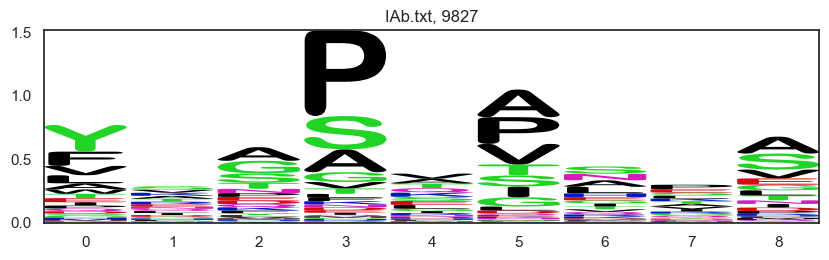

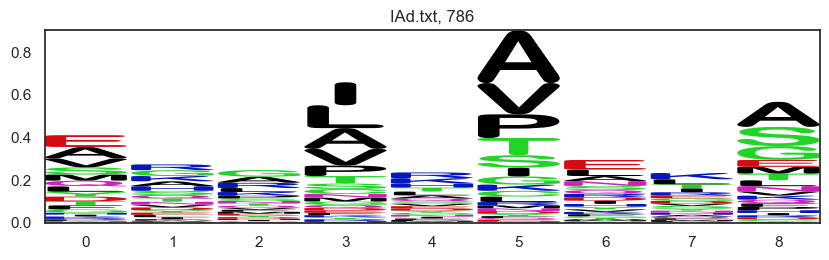

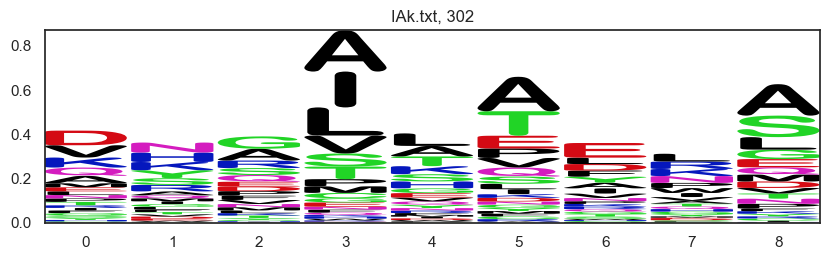

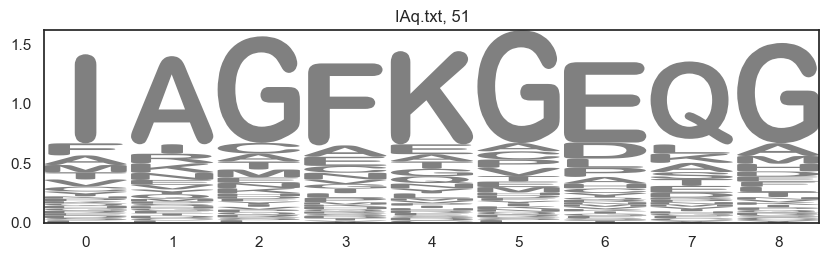

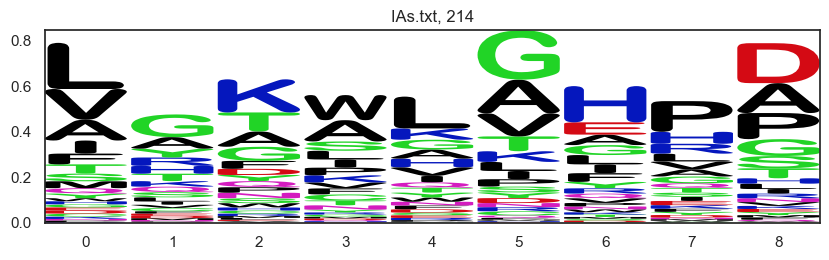

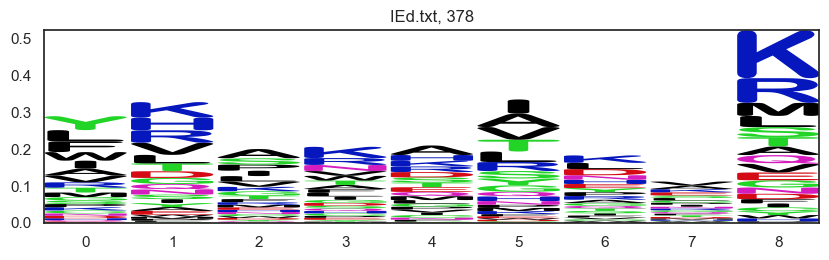

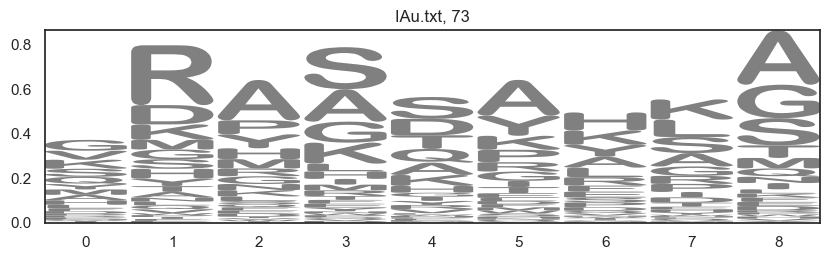

In [212]:
for target_file in only_files:
    df = pd.read_csv(f"{ALLELE_FILES}{target_file}",comment='#', sep='\t')
    df = df[df.Core_best.notna()]
    make_logo_for_data(df.Core_best.values, target_file)

In [196]:
tf = 'IAb.txt'
df = pd.read_csv(f"{ALLELE_FILES}{tf}",comment='#', sep='\t')

In [209]:
df

,Peptide,Context,BestAllele,%Rank_best,Core_best,CoreP1_best,SubSpec_best,%Rank_H2_Aa_u__H2_Ab_u,CoreP1_H2_Aa_u__H2_Ab_u,SubSpec_H2_Aa_u__H2_Ab_u
1,SKYLATASTMDHA,NaN,H2_Aa_u__H2_Ab_u,8.58,ATASTMDHA,5.0,1.0,8.58,5.0,1.0
2,RHRDTGILDSLGRFFSG,NaN,H2_Aa_u__H2_Ab_u,97.50,HRDTGILDS,2.0,1.0,97.50,2.0,1.0
3,TGILDSLGRFFSG,NaN,H2_Aa_u__H2_Ab_u,68.20,DSLGRFFSG,5.0,1.0,68.20,5.0,1.0
4,GRFFGGDRGAPKRG,NaN,H2_Aa_u__H2_Ab_u,56.50,GDRGAPKRG,6.0,1.0,56.50,6.0,1.0
5,YGSLPQKSHGRTQ,NaN,H2_Aa_u__H2_Ab_u,54.10,PQKSHGRTQ,5.0,1.0,54.10,5.0,1.0
...,...,...,...,...,...,...,...,...,...,...
114,SRGGASQYRPSQ,NaN,H2_Aa_u__H2_Ab_u,44.00,GGASQYRPS,3.0,1.0,44.00,3.0,1.0
116,ASQKRPSQRHGSKY,NaN,H2_Aa_u__H2_Ab_u,10.10,KRPSQRHGS,4.0,1.0,10.10,4.0,1.0
117,ASQYRPSQRHGSKY,NaN,H2_Aa_u__H2_Ab_u,13.90,YRPSQRHGS,4.0,1.0,13.90,4.0,1.0
118,ASQARPSQRHGSKY,NaN,H2_Aa_u__H2_Ab_u,11.50,ARPSQRHGS,4.0,1.0,11.50,4.0,1.0
